# Day 29 — KPI Development
Retail Sales & Customer Performance Analysis | Technosignia

Objective: Convert raw analysis into management-level KPIs. Day 28 remains pending. Source: Institute_Day29.pdf; Day 24 transformed data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image
import seaborn as sns
sns.set_theme(style='whitegrid')
df = pd.read_csv('transformed_retail_sales.csv', parse_dates=['Order_Date'])
assert df[['Sales','Order_ID','Customer_Name','Quantity','Order_Date']].notna().all().all()
assert np.allclose(df.Sales, df.Quantity * df.Unit_Price)
print('Shape:', df.shape)
print('Period:', df.Order_Date.min().date(), 'to', df.Order_Date.max().date())
display(df.head())

Shape: (30, 27)
Period: 2026-10-01 to 2026-10-28


,Order_ID,Order_Date,Customer_Name,City,Category,Product,Quantity,Unit_Price,Sales,Customer_Rating,Customer_Rating_Was_Imputed,Year,Month,Month_Name,Quarter,Profit_Margin,Order_Value,Customer_Total_Spending,Customer_Segment,Sales_Category,Customer_Order_Count,Customer_Type,Product_Total_Sales,Product_Performance,Order_Size,Day_Name,Is_Weekend
0,ORD001,2026-10-02,Rahul,Mumbai,Clothing,T-Shirt,2,650,1300,5.0,False,2026,10,October,4,NaN,1300,13350,Medium Value,Medium,5,Repeat,14950,Low,Small,Friday,False
1,ORD002,2026-10-03,Neha,Nagpur,Grocery,Rice,3,320,960,3.0,False,2026,10,October,4,NaN,960,10700,Medium Value,Low,5,Repeat,6720,Low,Medium,Saturday,True
2,ORD003,2026-10-04,Vikram,Nashik,Home,Lamp,4,1100,4400,4.0,False,2026,10,October,4,NaN,4400,13350,Medium Value,High,5,Repeat,24200,High,Medium,Sunday,True
3,ORD004,2026-10-05,Priya,Pune,Electronics,Headphones,5,1500,7500,5.0,False,2026,10,October,4,NaN,7500,17780,High Value,High,5,Repeat,36000,High,Large,Monday,False
4,ORD005,2026-10-06,Arjun,Pune,Clothing,T-Shirt,1,650,650,4.0,False,2026,10,October,4,NaN,650,12450,Medium Value,Low,5,Repeat,14950,Low,Small,Tuesday,False


In [2]:
revenue = df.Sales.sum()
orders = df.Order_ID.nunique()
customers = df.Customer_Name.nunique()
def divide(a,b):
    return a/b if pd.notna(a) and pd.notna(b) and b != 0 else np.nan
profit = df.Profit.sum() if 'Profit' in df and df.Profit.notna().all() else np.nan
aov = divide(revenue,orders)
margin = divide(profit,revenue)*100
monthly = df.groupby(df.Order_Date.dt.to_period('M')).Sales.sum().sort_index()
current = monthly.index.max()
previous = monthly.get(current-1,np.nan)
growth = divide(monthly.loc[current]-previous,previous)*100
units = df.Quantity.sum()
spending = divide(revenue,customers)
frequency = df.groupby('Customer_Name').Order_ID.nunique()
repeat = divide((frequency>1).sum(),customers)*100
assert np.isclose(monthly.sum(),revenue)
assert np.isclose(aov*orders,revenue)
assert np.isclose(spending*customers,revenue)
assert np.isclose(df.groupby('Category').Sales.sum().sum(),revenue)
print('Revenue reconciliation checks passed.')

Revenue reconciliation checks passed.


## KPI 1 — Total Revenue
**Definition:** Sum of recorded sales.  
**Formula:** SUM(Sales).  
**Business meaning:** Sales generated in the period.  
**Why management needs it:** Track revenue performance.

In [3]:
print('Total Revenue:', 'N/A' if pd.isna(revenue) else f'{revenue:,.2f} INR')

Total Revenue: 81,870.00 INR


## KPI 2 — Total Profit
**Definition:** Sum of recorded profit.  
**Formula:** SUM(Profit).  
**Business meaning:** Earnings after applicable costs.  
**Why management needs it:** Evaluate financial viability.

In [4]:
print('Total Profit:', 'N/A' if pd.isna(profit) else f'{profit:,.2f} INR')

Total Profit: N/A


## KPI 3 — Total Orders
**Definition:** Number of unique orders.  
**Formula:** COUNT DISTINCT(Order_ID).  
**Business meaning:** Transaction volume.  
**Why management needs it:** Plan operations and demand.

In [5]:
print('Total Orders:', 'N/A' if pd.isna(orders) else f'{orders:,.2f} count')

Total Orders: 30.00 count


## KPI 4 — Total Customers
**Definition:** Number of unique customers (name proxy).  
**Formula:** COUNT DISTINCT(Customer_Name).  
**Business meaning:** Observed customer base.  
**Why management needs it:** Assess customer reach.

In [6]:
print('Total Customers:', 'N/A' if pd.isna(customers) else f'{customers:,.2f} count')

Total Customers: 6.00 count


## KPI 5 — Average Order Value
**Definition:** Revenue per unique order.  
**Formula:** Revenue / Orders.  
**Business meaning:** Typical transaction value.  
**Why management needs it:** Guide upselling and pricing.

In [7]:
print('Average Order Value:', 'N/A' if pd.isna(aov) else f'{aov:,.2f} INR')

Average Order Value: 2,729.00 INR


## KPI 6 — Profit Margin
**Definition:** Profit as a percentage of revenue.  
**Formula:** Profit / Revenue × 100.  
**Business meaning:** Profitability per rupee of sales.  
**Why management needs it:** Monitor cost efficiency.

In [8]:
print('Profit Margin:', 'N/A' if pd.isna(margin) else f'{margin:,.2f} %')

Profit Margin: N/A


## KPI 7 — Growth %
**Definition:** Change from previous calendar month.  
**Formula:** (Current - Previous) / Previous × 100.  
**Business meaning:** Month-over-month revenue change.  
**Why management needs it:** Monitor business momentum.

In [9]:
print('Growth %:', 'N/A' if pd.isna(growth) else f'{growth:,.2f} %')

Growth %: N/A


## KPI 8 — Total Units Sold
**Definition:** Sum of quantities.  
**Formula:** SUM(Quantity).  
**Business meaning:** Volume of merchandise sold.  
**Why management needs it:** Plan stock replenishment.

In [10]:
print('Total Units Sold:', 'N/A' if pd.isna(units) else f'{units:,.2f} count')

Total Units Sold: 90.00 count


## KPI 9 — Average Customer Spending
**Definition:** Revenue per observed customer.  
**Formula:** Revenue / Customers.  
**Business meaning:** Spending per customer name.  
**Why management needs it:** Guide customer targeting.

In [11]:
print('Average Customer Spending:', 'N/A' if pd.isna(spending) else f'{spending:,.2f} INR')

Average Customer Spending: 13,645.00 INR


## KPI 10 — Observed Repeat Customer Rate
**Definition:** Share of names with multiple orders.  
**Formula:** Repeat names / Customers × 100.  
**Business meaning:** Repeat purchasing in observed period.  
**Why management needs it:** Guide loyalty initiatives.

In [12]:
print('Observed Repeat Customer Rate:', 'N/A' if pd.isna(repeat) else f'{repeat:,.2f} %')

Observed Repeat Customer Rate: 100.00 %


## Limitations
Profit and cost are absent; Profit_Margin is blank. Growth requires a previous calendar month with nonzero revenue. Customer_Name is a proxy, not a unique customer identifier. Repeat rate is not long-term retention.

In [13]:
metadata = [('Total Revenue', 'Sum of recorded sales', 'SUM(Sales)', 'Sales generated in the period', 'Track revenue performance', 'revenue', 'INR'), ('Total Profit', 'Sum of recorded profit', 'SUM(Profit)', 'Earnings after applicable costs', 'Evaluate financial viability', 'profit', 'INR'), ('Total Orders', 'Number of unique orders', 'COUNT DISTINCT(Order_ID)', 'Transaction volume', 'Plan operations and demand', 'orders', 'count'), ('Total Customers', 'Number of unique customers (name proxy)', 'COUNT DISTINCT(Customer_Name)', 'Observed customer base', 'Assess customer reach', 'customers', 'count'), ('Average Order Value', 'Revenue per unique order', 'Revenue / Orders', 'Typical transaction value', 'Guide upselling and pricing', 'aov', 'INR'), ('Profit Margin', 'Profit as a percentage of revenue', 'Profit / Revenue × 100', 'Profitability per rupee of sales', 'Monitor cost efficiency', 'margin', '%'), ('Growth %', 'Change from previous calendar month', '(Current - Previous) / Previous × 100', 'Month-over-month revenue change', 'Monitor business momentum', 'growth', '%'), ('Total Units Sold', 'Sum of quantities', 'SUM(Quantity)', 'Volume of merchandise sold', 'Plan stock replenishment', 'units', 'count'), ('Average Customer Spending', 'Revenue per observed customer', 'Revenue / Customers', 'Spending per customer name', 'Guide customer targeting', 'spending', 'INR'), ('Observed Repeat Customer Rate', 'Share of names with multiple orders', 'Repeat names / Customers × 100', 'Repeat purchasing in observed period', 'Guide loyalty initiatives', 'repeat', '%')]
reasons = {'profit':'No complete Profit column or cost data','margin':'Profit unavailable','growth':'Previous calendar month unavailable or zero','customers':'Customer_Name proxy','spending':'Customer_Name proxy','repeat':'Observed period; Customer_Name proxy'}
summary = pd.DataFrame([{'KPI':r[0],'Definition':r[1],'Formula':r[2],'Business_Meaning':r[3],'Management_Importance':r[4],'Value':globals()[r[5]],'Unit':r[6],'Status':'Unavailable' if pd.isna(globals()[r[5]]) else 'Calculated','Notes':reasons.get(r[5],'')} for r in metadata])
summary.to_csv('KPI_Summary.csv',index=False)
display(summary[['KPI','Value','Unit','Status','Notes']])

,KPI,Value,Unit,Status,Notes
0,Total Revenue,81870.0,INR,Calculated,
1,Total Profit,NaN,INR,Unavailable,No complete Profit column or cost data
2,Total Orders,30.0,count,Calculated,
3,Total Customers,6.0,count,Calculated,Customer_Name proxy
4,Average Order Value,2729.0,INR,Calculated,
5,Profit Margin,NaN,%,Unavailable,Profit unavailable
6,Growth %,NaN,%,Unavailable,Previous calendar month unavailable or zero
7,Total Units Sold,90.0,count,Calculated,
8,Average Customer Spending,13645.0,INR,Calculated,Customer_Name proxy
9,Observed Repeat Customer Rate,100.0,%,Calculated,Observed period; Customer_Name proxy


## Visualizations
Category revenue identifies concentration; customer revenue supports targeting; monthly revenue shows observed coverage only, not a trend. Order value distribution shows transaction variability.

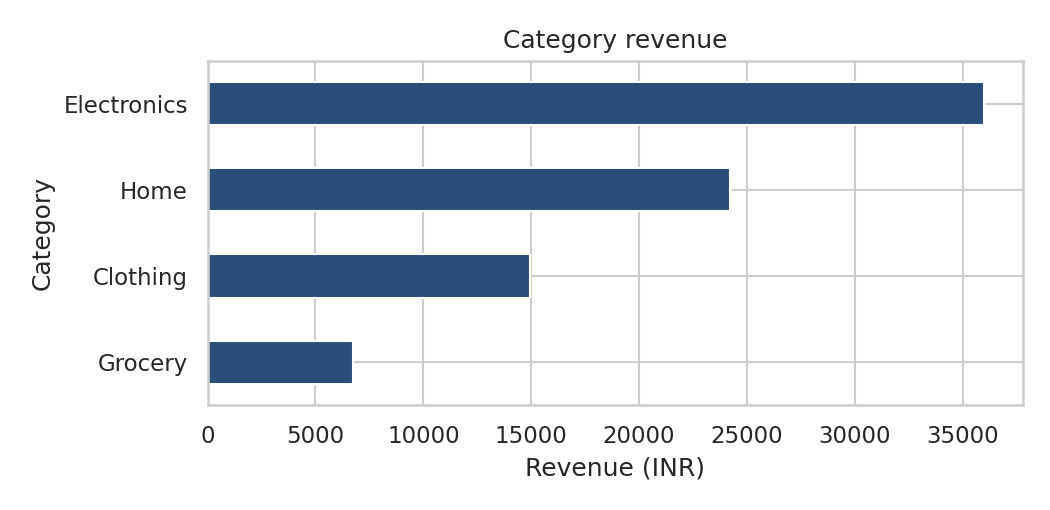

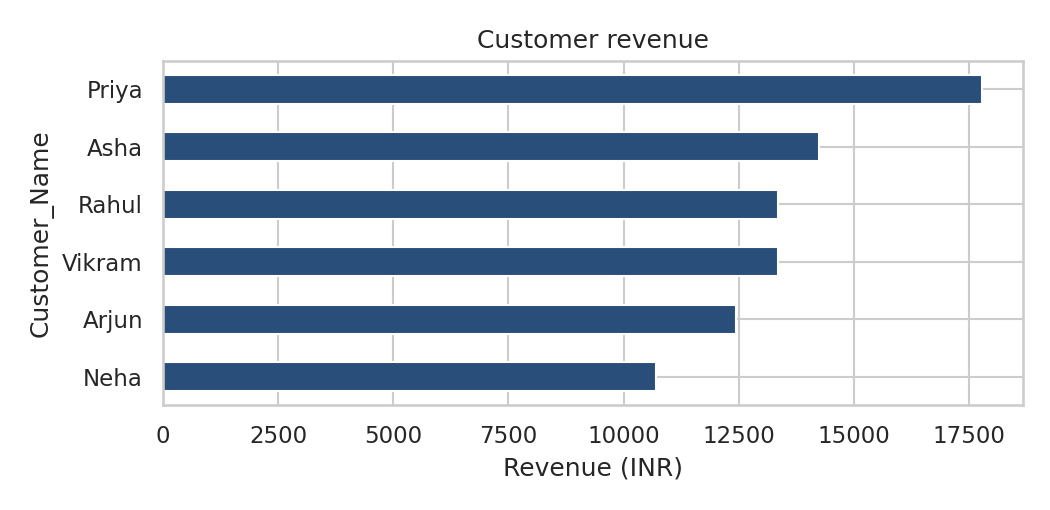

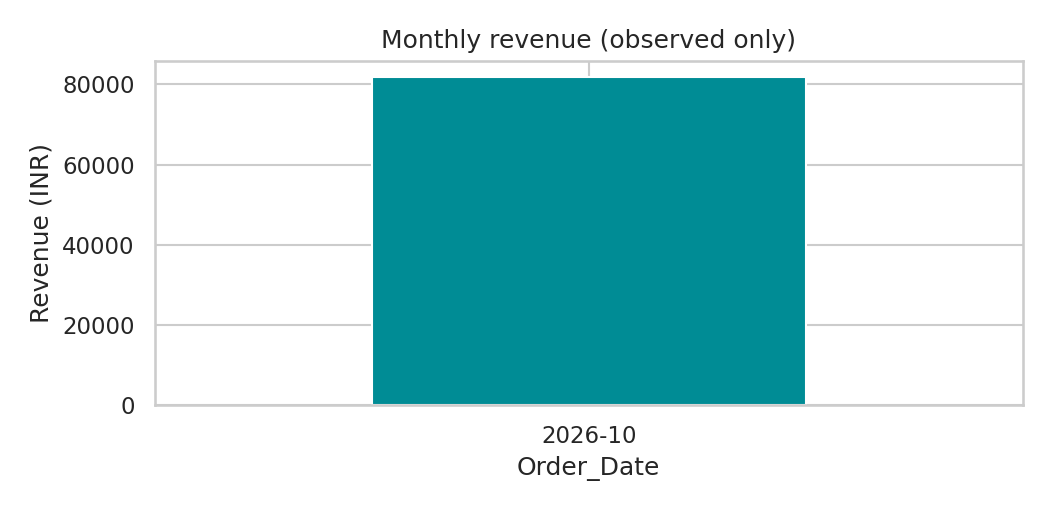

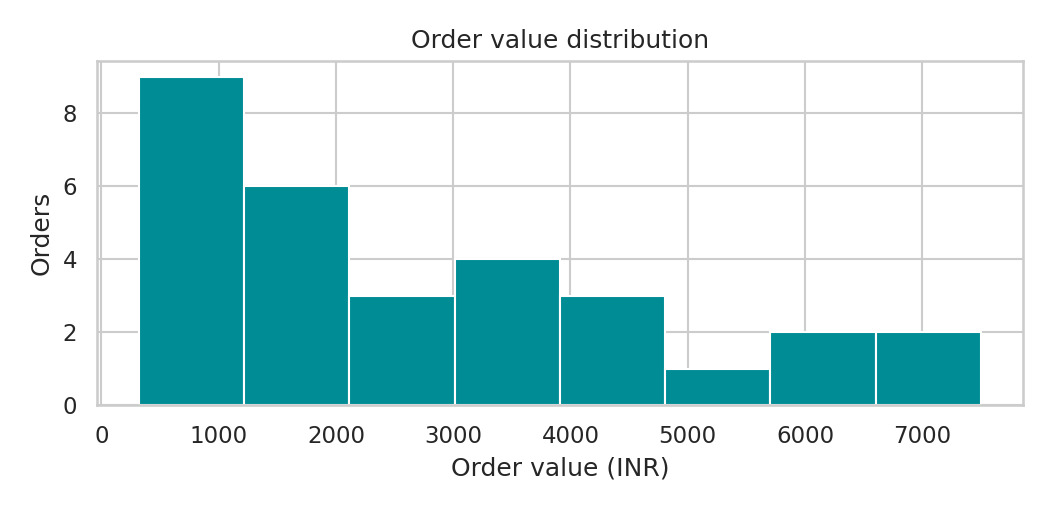

In [14]:
Path('charts').mkdir(exist_ok=True)
series = [(df.groupby('Category').Sales.sum().sort_values(), 'Category revenue','01_category'),(df.groupby('Customer_Name').Sales.sum().sort_values(),'Customer revenue','02_customer'),(monthly.rename(index=str),'Monthly revenue (observed only)','03_monthly'),(df.groupby('Order_ID').Sales.sum(),'Order value distribution','04_order_value')]
for values,title,name in series:
    fig,ax=plt.subplots(figsize=(7,3.4))
    if name=='04_order_value': ax.hist(values,bins=8,color='#008C95'); ax.set_xlabel('Order value (INR)'); ax.set_ylabel('Orders')
    elif name=='03_monthly': values.plot.bar(ax=ax,color='#008C95',rot=0); ax.set_ylabel('Revenue (INR)')
    else: values.plot.barh(ax=ax,color='#294E79'); ax.set_xlabel('Revenue (INR)')
    ax.set_title(title); fig.tight_layout(); path=f'charts/{name}.png'; fig.savefig(path,dpi=150); plt.close(fig); display(Image(filename=path))

## Insights and recommendations
Revenue is concentrated in Electronics and Home. Test cross-selling to raise order value. Collect unique customer IDs, cost/profit data and consecutive months of transactions before assessing profitability or growth. Do not interpret missing KPIs as zero.